## Importing relevant libraries

In [13]:
import os 
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Rescaling, Conv2D, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

## Defining settings

In [14]:
data_dir = "/kaggle/input/datasets/vencerlanz09/plastic-paper-garbage-bag-synthetic-images/Bag Classes/Bag Classes"

batch_size = 32
img_height = 180
img_width = 180

## Data Loading, Preparations and Checks

In [15]:
# Loading the training set
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3, 
    subset="training",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size
)


# Validation set
validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3, 
    subset="validation",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size
)

Found 15000 files belonging to 3 classes.
Using 10500 files for training.
Found 15000 files belonging to 3 classes.
Using 4500 files for validation.


In [16]:
# View the class names
class_names = train_ds.class_names
print(class_names)

['Garbage Bag Images', 'Paper Bag Images', 'Plastic Bag Images']


### Visualizing classes

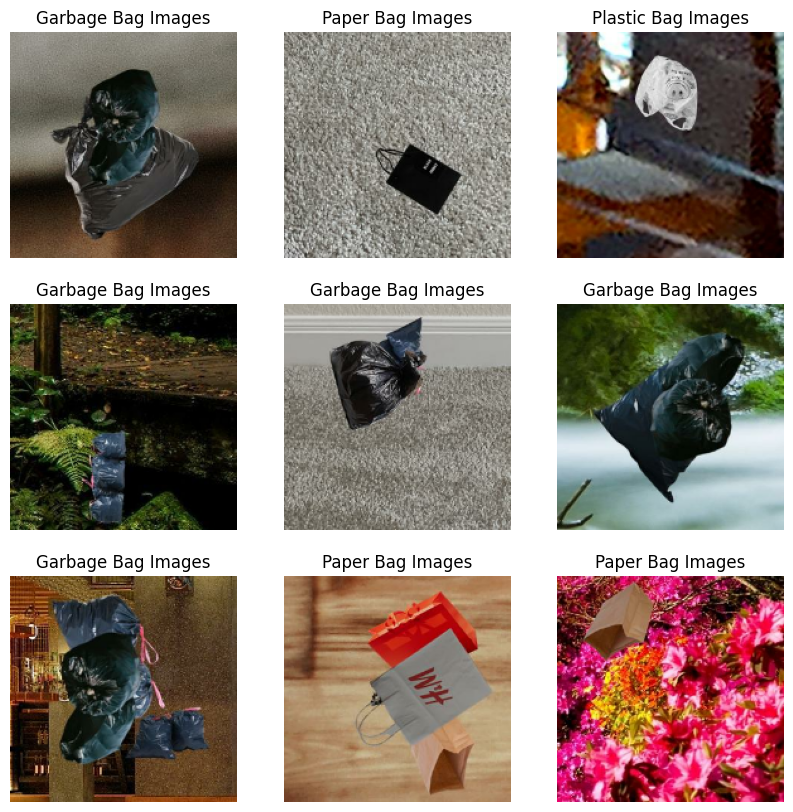

In [17]:
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
        

In [18]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)
    print(labels_batch.shape)
    break

(32, 180, 180, 3)
(32,)


## Define the neural network model

In [19]:
model = tf.keras.Sequential([
                            Input(shape=(180, 180, 3)),
                            Rescaling(1./255),
                            Conv2D(32, 3, activation="relu"),
                            tf.keras.layers.MaxPooling2D(),
                            Conv2D(32, 3, activation="relu"),
                            tf.keras.layers.MaxPooling2D(),
                            Conv2D(32, 3, activation="relu"),
                            tf.keras.layers.MaxPooling2D(),
                            Flatten(),
                            Dense(128, activation='relu'),
                            Dense(64, activation='relu'),
                            # Output layer
                            Dense(3, activation='softmax')
])

In [20]:
# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [21]:
# Add a model checkpint
checkpoint = ModelCheckpoint(
    'best_model.h5', # File to save the best model  
    monitor = 'val_loss',
    save_best_only = True
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

## Train the model

In [22]:
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs = 50, 
    callbacks = [checkpoint, early_stopping]
)

Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7063 - loss: 0.6231

329/329 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.8184 - loss: 0.4375 - val_accuracy: 0.8909 - val_loss: 0.2930
Epoch 2/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.8981 - loss: 0.2644 - val_accuracy: 0.8629 - val_loss: 0.3362
Epoch 3/50
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9082 - loss: 0.2345

329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9248 - loss: 0.1988 - val_accuracy: 0.9284 - val_loss: 0.2048
Epoch 4/50
326/329 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9393 - loss: 0.1514

329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9424 - loss: 0.1497 - val_accuracy: 0.9213 - val_loss: 0.2007
Epoch 5/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9577 - loss: 0.1126 - val_accuracy: 0.9262 - val_loss: 0.2082
Epoch 6/50
327/329 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9644 - loss: 0.1007

329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9659 - loss: 0.0955 - val_accuracy: 0.9396 - val_loss: 0.1927
Epoch 7/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9756 - loss: 0.0672 - val_accuracy: 0.9193 - val_loss: 0.2626
Epoch 8/50
327/329 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9709 - loss: 0.0794

329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9753 - loss: 0.0681 - val_accuracy: 0.9438 - val_loss: 0.1842
Epoch 9/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9723 - loss: 0.0789 - val_accuracy: 0.9549 - val_loss: 0.1938
Epoch 10/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9816 - loss: 0.0552 - val_accuracy: 0.9289 - val_loss: 0.2173
Epoch 11/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9877 - loss: 0.0391 - val_accuracy: 0.9447 - val_loss: 0.2286
Epoch 12/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9819 - loss: 0.0553 - val_accuracy: 0.9409 - val_loss: 0.2073
Epoch 13/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9830 - loss: 0.0453 - val_accuracy: 0.9507 - val_loss: 0.1937


## Visualizing the training process
**Accuracy over time**

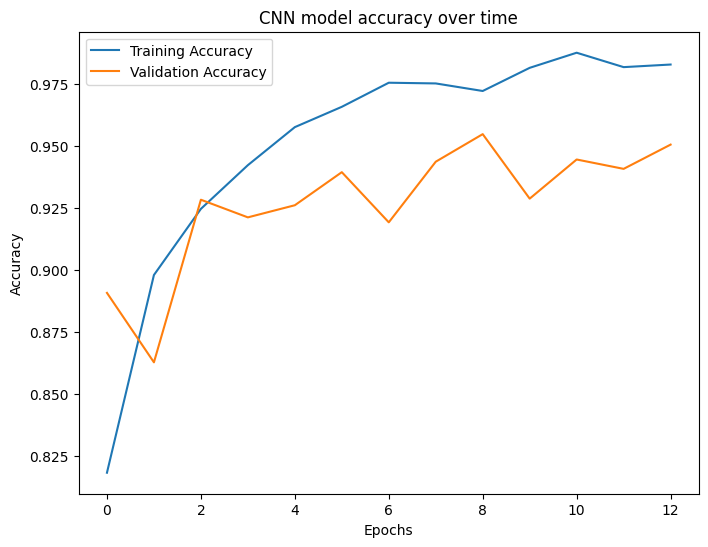

In [23]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN model accuracy over time')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**Loss over time**

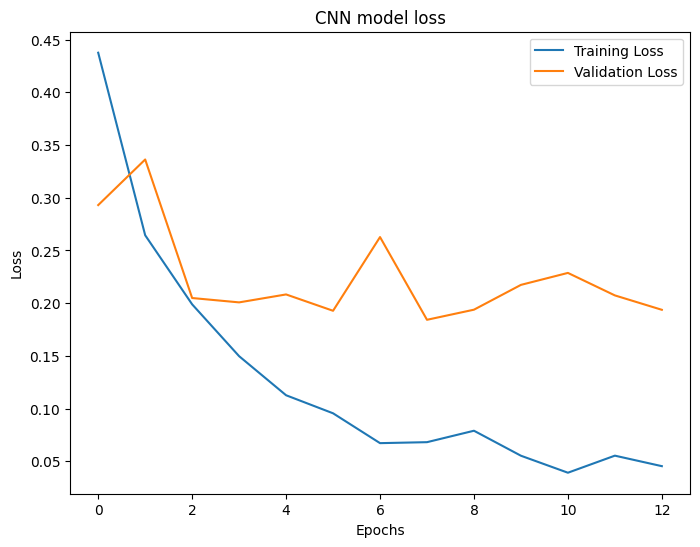

In [24]:
plt.figure(figsize=(8,6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("CNN model loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Testing the model using external images

In [33]:
from ipywidgets import FileUpload     
from IPython.display import display, clear_output   
import ipywidgets
import PIL.Image
from io import BytesIO


upload = FileUpload(
     accept='.jpg, .jpeg',
     multiple=True,
    description='Upload Images'
)


output = ipywidgets.Output()

def on_upload(change):
    with output:
        clear_output(wait=True)
        for info in upload.value:
            name = info['name']
            content = info ['content']
            img = PIL.Image.open(BytesIO(content))
            img_resized = img.resize((img_width, img_height))
            img_array = tf.keras.utils.img_to_array(img_resized)
            img_array = tf.expand_dims(img_array, 0)


            predictions = model.predict(img_array)
            score = tf.nn.softmax(predictions[0])

            print(f"Image: {name} Belongs to '{class_names[np.argmax(score)]}' with {100 * np.max(score)}% confidence")


upload.observe(on_upload, names='value')
display(upload, output)

FileUpload(value=(), accept='.jpg, .jpeg', description='Upload Images', multiple=True)

Output()